In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
R=0.5
wavelength = 632.8*1e-9
n=1.5 #glas
f=-R/(n-1) 
z=3.995
L=np.array([0.51, 0.75, 0.987])
w=1e-3*np.array([5, 6, 9])

def w0_plus(w, A, B, wavelength):
    inner_root = np.sqrt( (w**2 / (2*A**2))**2 - (wavelength*B / (np.pi*A))**2 )
    return np.sqrt( (w**2 / (2*A**2)) + inner_root )

def w0_minus(w, A, B, wavelength):
    inner_root = np.sqrt( (w**2 / (2*A**2))**2 - (wavelength*B / (np.pi*A))**2 )
    return np.sqrt( (w**2 / (2*A**2)) - inner_root )

l1=L/2
l2=z-L/2

#ohne linse- nur ausbreitung
A_a = 1
B_a = z
w0_ausserhalb=w0_minus(w, A_a, B_a, wavelength)
print("Ausserhalb w0:", 1000*w0_ausserhalb)
print("w(Z) ohne linse: ", 1000*w0_ausserhalb*np.sqrt(1+(z/(np.pi*w0_ausserhalb/wavelength))**2))

# mit linse 
# innerhalb:
A = 1 - l2/f
B = l1 + l2 - (l1*l2)/f
w0_innerhalb=w0_minus(w, A, B, wavelength)
print("Innerhalb w0: ", 1000*w0_innerhalb)
print("w(Z) mit linse: ", 1000*w0_innerhalb*np.sqrt(1+(z/(np.pi*w0_innerhalb/wavelength))**2))



Ausserhalb Minus: [0.16102329 0.13415001 0.0894154 ]
w(Z) ohne linse:  [0.1610253  0.13415242 0.08941902]
Innerhalb Minus:  [0.20316358 0.18146954 0.1283494 ]
w(Z) mit linse:  [0.20316518 0.18147132 0.12835192]


In [12]:
#von oben plus fehler
import numpy as np

# --- 1. Gegebene Parameter (als fehlerfrei angenommen) ---
R = 0.5
wavelength = 632.8 * 1e-9
n = 1.5
f = -R / (n - 1)

# --- 2. Messwerte ---
z = 3.995
L = np.array([0.51, 0.75, 0.987])
w = 1e-3 * np.array([5.0, 6.0, 9.0])

# --- 3. Absolute Fehler (in Meter) ---
dz = 0.01        # Fehler von z (1 cm)
dL = 0.01        # Fehler von L (1 cm)
dw = 0.5 * 1e-3  # Fehler von w_messung (0.5 mm)

# --- Ursprüngliche Formel ---
def w0_minus(w, A, B, wavelength):
    inner_root = np.sqrt( (w**2 / (2*A**2))**2 - (wavelength*B / (np.pi*A))**2 )
    return np.sqrt( (w**2 / (2*A**2)) - inner_root )

# --- Wrapper-Funktionen für die Modelle ---
# Diese machen es einfacher, w0 direkt in Abhängigkeit von w, z und L aufzurufen
def calc_w0_ohne(w_val, z_val):
    A = 1
    B = z_val
    return w0_minus(w_val, A, B, wavelength)

def calc_w0_mit(w_val, z_val, L_val):
    l1 = L_val / 2
    l2 = z_val - L_val / 2
    A = 1 - l2/f
    B = l1 + l2 - (l1*l2)/f
    return w0_minus(w_val, A, B, wavelength)

# --- 4. Numerische Gaußsche Fehlerfortpflanzung ---
h = 1e-8 # Sehr kleiner Schritt für numerische Ableitung

# A) MODELL OHNE LINSE
w0_ohne = calc_w0_ohne(w, z)

# Partielle Ableitungen (Steigung berechnen)
dw0_dw_ohne = (calc_w0_ohne(w + h, z) - calc_w0_ohne(w - h, z)) / (2 * h)
dw0_dz_ohne = (calc_w0_ohne(w, z + h) - calc_w0_ohne(w, z - h)) / (2 * h)

# Gauß-Fehler aus den Ableitungen und den Messunsicherheiten
err_w0_ohne = np.sqrt((dw0_dw_ohne * dw)**2 + (dw0_dz_ohne * dz)**2)

# B) MODELL MIT LINSE
w0_mit = calc_w0_mit(w, z, L)

# Partielle Ableitungen (Steigung berechnen)
dw0_dw_mit = (calc_w0_mit(w + h, z, L) - calc_w0_mit(w - h, z, L)) / (2 * h)
dw0_dz_mit = (calc_w0_mit(w, z + h, L) - calc_w0_mit(w, z - h, L)) / (2 * h)
dw0_dL_mit = (calc_w0_mit(w, z, L + h) - calc_w0_mit(w, z, L - h)) / (2 * h)

# Gauß-Fehler aus den Ableitungen und den Messunsicherheiten
err_w0_mit = np.sqrt((dw0_dw_mit * dw)**2 + (dw0_dz_mit * dz)**2 + (dw0_dL_mit * dL)**2)

# --- 5. Übersichtliche Ausgabe ---
print("--- OHNE LINSE (Freiraum) ---")
for i in range(len(L)):
    print(f"L = {L[i]:.3f} m: w0 = {w0_ohne[i]*1000:.3f} +/- {err_w0_ohne[i]*1000:.3f} mm")

print("\n--- MIT LINSE (Auskoppelspiegel) ---")
for i in range(len(L)):
    print(f"L = {L[i]:.3f} m: w0 = {w0_mit[i]*1000:.3f} +/- {err_w0_mit[i]*1000:.3f} mm")

--- OHNE LINSE (Freiraum) ---
L = 0.510 m: w0 = 0.161 +/- 0.016 mm
L = 0.750 m: w0 = 0.134 +/- 0.011 mm
L = 0.987 m: w0 = 0.089 +/- 0.005 mm

--- MIT LINSE (Auskoppelspiegel) ---
L = 0.510 m: w0 = 0.203 +/- 0.022 mm
L = 0.750 m: w0 = 0.181 +/- 0.016 mm
L = 0.987 m: w0 = 0.128 +/- 0.007 mm


In [11]:
import numpy as np

wavelength = 632.8 * 1e-9
R = 0.5 
n = 1.5 
f = -R / (n - 1)  # f = -1.0 m (plankonkave Linse)

z = 3.995 # m (Abstand Resonatormitte bis Draht)
L = np.array([0.51, 0.75, 0.987])

# 1. Schritt: Das REIN THEORETISCHE w0 berechnen (nur aus L und R)
z_R_theo = np.sqrt((L / 2) * (R - L / 2))
w0_theo = np.sqrt((wavelength * z_R_theo) / np.pi)

print("--- THEORETISCHE TAILLE IM RESONATOR ---")
print(f"w0_theo: {np.round(w0_theo * 1000, 3)} mm\n")

# 2. Schritt: Vorwärts-Propagation mit der allgemeinen ABCD-Formel
def w_out_abcd(w0, A, B, wavelength):
    return w0 * np.sqrt(A**2 + (wavelength * B / (np.pi * w0**2))**2)

l1 = L / 2
l2 = z - L / 2

# --- OHNE LINSE (Freiraum) ---
A_ohne = 1
B_ohne = z
w_z_ohne = w_out_abcd(w0_theo, A_ohne, B_ohne, wavelength)

# --- MIT LINSE (ABCD Matrix) ---
A_mit = 1 - l2 / f
B_mit = l1 + l2 - (l1 * l2) / f
w_z_mit = w_out_abcd(w0_theo, A_mit, B_mit, wavelength)

print("--- THEORETISCHER RADIUS BEI z = 3.995 m ---")
print(f"w(z) OHNE Linse: {np.round(w_z_ohne * 1000, 2)} mm")
print(f"w(z) MIT Linse:  {np.round(w_z_mit * 1000, 2)} mm")

--- THEORETISCHE TAILLE IM RESONATOR ---
w0_theo: [0.224 0.209 0.107] mm

--- THEORETISCHER RADIUS BEI z = 3.995 m ---
w(z) OHNE Linse: [3.59 3.86 7.53] mm
w(z) MIT Linse:  [ 4.57  5.25 10.8 ] mm


In [16]:
import numpy as np

# --- 1. Gegebene Parameter ---
wavelength = 632.8 * 1e-9 # m

# --- 2. Messwerte für Aufgabe 4a/4b (Innerhalb des Resonators) ---
L = np.array([0.5, 0.75, 0.987]) # Resonatorlängen in m
z = np.array([0.213, 0.287, 0.425]) # Abstand Resonatormitte zu Draht in m
w_messung = np.array([0.31, 0.36, 0.76]) * 1e-3 # Bündelradius am Draht in m

# --- 3. Messfehler ---
dz = 0.01 # m (Fehler bei der Längenmessung mit dem Maßband: 1 cm)
dw = 0.01 * 1e-3 # m (Fehler der Messuhr: 0.01 mm)

# --- 4. Auswertungsfunktionen (Freiraum: A=1, B=z) ---
def w0_calc_plus(w, z_val, wavelength):
    # max(..., 0) verhindert Abstürze bei numerischen Minischwankungen
    inner = np.sqrt(max((w**2 / 2)**2 - (wavelength * z_val / np.pi)**2, 0)) 
    return np.sqrt((w**2 / 2) + inner)

def w0_calc_minus(w, z_val, wavelength):
    inner = np.sqrt(max((w**2 / 2)**2 - (wavelength * z_val / np.pi)**2, 0))
    return np.sqrt((w**2 / 2) - inner)

# --- 5. Berechnung der Taillen w0 inkl. Fallunterscheidung ---
w0_messung_val = np.zeros(3)
w0_messung_val[0] = w0_calc_plus(w_messung[0], z[0], wavelength)  
w0_messung_val[1] = w0_calc_minus(w_messung[1], z[1], wavelength) 
w0_messung_val[2] = w0_calc_minus(w_messung[2], z[2], wavelength) 

# --- 6. Numerische Fehlerfortpflanzung (Gauß) ---
h = 1e-8
err_w0 = np.zeros(3)

# Fehler für Wert 1 (Plus-Formel)
dw0_dw_1 = (w0_calc_plus(w_messung[0] + h, z[0], wavelength) - w0_calc_plus(w_messung[0] - h, z[0], wavelength)) / (2*h)
dw0_dz_1 = (w0_calc_plus(w_messung[0], z[0] + h, wavelength) - w0_calc_plus(w_messung[0], z[0] - h, wavelength)) / (2*h)
err_w0[0] = np.sqrt((dw0_dw_1 * dw)**2 + (dw0_dz_1 * dz)**2)

# Fehler für Wert 2 & 3 (Minus-Formel)
for i in [1, 2]:
    dw0_dw = (w0_calc_minus(w_messung[i] + h, z[i], wavelength) - w0_calc_minus(w_messung[i] - h, z[i], wavelength)) / (2*h)
    dw0_dz = (w0_calc_minus(w_messung[i], z[i] + h, wavelength) - w0_calc_minus(w_messung[i], z[i] - h, wavelength)) / (2*h)
    err_w0[i] = np.sqrt((dw0_dw * dw)**2 + (dw0_dz * dz)**2)

# --- 7. Ausgabe ---
print("--- ERGEBNISSE FÜR DAS PROTOKOLL ---")
for i in range(3):
    print(f"L = {L[i]:.3f} m: w0 = {w0_messung_val[i]*1000:.3f} +/- {err_w0[i]*1000:.3f} mm")

--- ERGEBNISSE FÜR DAS PROTOKOLL ---
L = 0.500 m: w0 = 0.264 +/- 0.020 mm
L = 0.750 m: w0 = 0.188 +/- 0.016 mm
L = 0.987 m: w0 = 0.114 +/- 0.003 mm


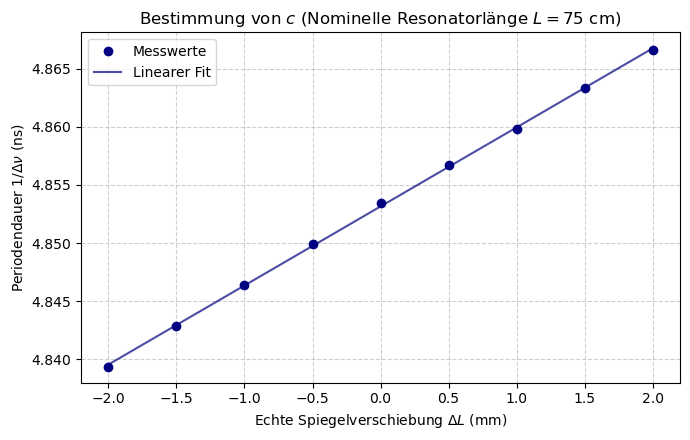

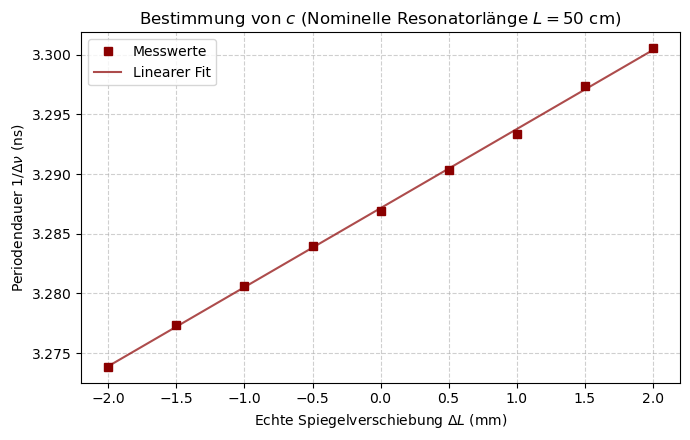

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ==========================================
# 1. MESSDATEN & UMRECHNUNG
# ==========================================
schrauben_schritte = np.array([4, 3, 2, 1, 0, -1, -2, -3, -4])

nu_75_MHz = np.array([206.64, 206.49, 206.34, 206.19, 206.04, 205.90, 205.77, 205.62, 205.48])
nu_50_MHz = np.array([305.45, 305.12, 304.82, 304.51, 304.24, 303.92, 303.64, 303.27, 302.98])

# Umrechnung: 1 Skalenteil = 0.5 mm echter Weg
delta_L_m = -schrauben_schritte * 0.5 * 1e-3 

y_75 = 1 / (nu_75_MHz * 1e6)
y_50 = 1 / (nu_50_MHz * 1e6)

# ==========================================
# 2. AUSWERTUNG (FIT)
# ==========================================
def linear_fit(x, m, b):
    return m * x + b

# Fit für 75 cm
popt_75, _ = curve_fit(linear_fit, delta_L_m, y_75)
m75, b75 = popt_75

# Fit für 50 cm
popt_50, _ = curve_fit(linear_fit, delta_L_m, y_50)
m50, b50 = popt_50

print(f"--- Ergebnisse für {label} ---")
print(f"  Lichtgeschwindigkeit c : ({c/1e8:.4f} +/- {err_c/1e8:.4f}) * 10^8 m/s")
print(f"  Anfangslänge L0        : ({L0*100:.2f} +/- {err_L0*100:.2f}) cm\n")

# ==========================================
# 3. PLOT 1: Für L = 75 cm
# ==========================================
plt.figure(figsize=(7, 4.5))
plt.plot(delta_L_m * 1000, y_75 * 1e9, 'o', color='navy', label='Messwerte')
plt.plot(delta_L_m * 1000, linear_fit(delta_L_m, m75, b75) * 1e9, '-', color='navy', alpha=0.7, label='Linearer Fit')

plt.title('Bestimmung von $c$ (Nominelle Resonatorlänge $L = 75$ cm)')
plt.xlabel('Echte Spiegelverschiebung $\Delta L$ (mm)')
plt.ylabel('Periodendauer $1 / \Delta \\nu$ (ns)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
# plt.savefig('schwebung_75cm.png', dpi=300) # Entferne das # zum Speichern
plt.show()

# ==========================================
# 4. PLOT 2: Für L = 50 cm
# ==========================================
plt.figure(figsize=(7, 4.5))
plt.plot(delta_L_m * 1000, y_50 * 1e9, 's', color='darkred', label='Messwerte')
plt.plot(delta_L_m * 1000, linear_fit(delta_L_m, m50, b50) * 1e9, '-', color='darkred', alpha=0.7, label='Linearer Fit')

plt.title('Bestimmung von $c$ (Nominelle Resonatorlänge $L = 50$ cm)')
plt.xlabel('Echte Spiegelverschiebung $\Delta L$ (mm)')
plt.ylabel('Periodendauer $1 / \Delta \\nu$ (ns)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
# plt.savefig('schwebung_50cm.png', dpi=300) # Entferne das # zum Speichern
plt.show()

--- ERGEBNISSE FÜR L = 75 cm ---
 Anstieg m : (6.814 +/- 0.045) ns/m
 y-Achse b : (4.853 +/- 0.000) ns
 c         : (2.935 +/- 0.020) * 10^8 m/s
 L0        : (71.22 +/- 0.47) cm

--- ERGEBNISSE FÜR L = 50 cm ---
 Anstieg m : (6.620 +/- 0.064) ns/m
 y-Achse b : (3.287 +/- 0.000) ns
 c         : (3.021 +/- 0.029) * 10^8 m/s
 L0        : (49.65 +/- 0.48) cm



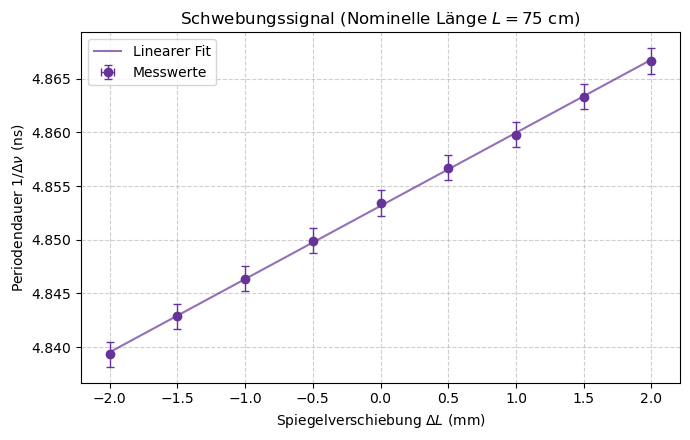

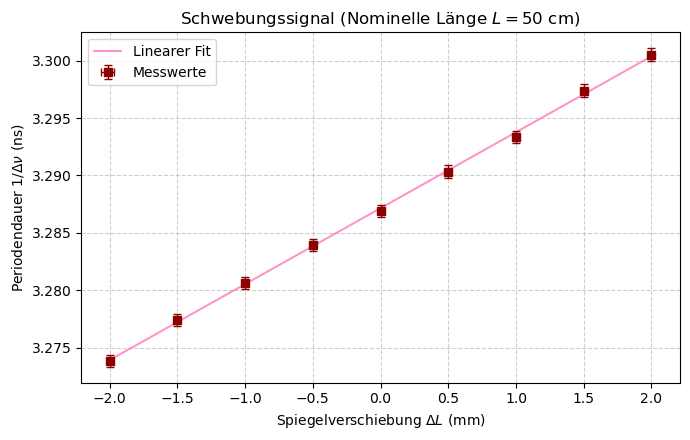

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ==========================================
# 1. MESSDATEN (Aufgabe 5)
# ==========================================
# Skalenteile an der Mikrometerschraube
schritte_75 = np.array([4, 3, 2, 1, 0, -1, -2, -3, -4])
nu_75_MHz = np.array([206.64, 206.49, 206.34, 206.19, 206.04, 205.90, 205.77, 205.62, 205.48])

schritte_50 = np.array([4, 3, 2, 1, 0, -1, -2, -3, -4])
nu_50_MHz = np.array([305.45, 305.12, 304.82, 304.51, 304.24, 303.92, 303.64, 303.27, 302.98])

# ==========================================
# 2. UMRECHNUNG IN SI-EINHEITEN
# ==========================================
# Wichtig: 1 Skalenteil entspricht 0,5 mm Längenänderung.
# Ein positiver Schritt an der Schraube = Resonator wird verkürzt (daher das Minus)

err_L_m = 0.01 * 1e-3 

# Fehler Frequenz: 0.05 MHz (50 kHz)
err_nu_MHz = 0.05 

# Umrechnung in SI-Einheiten
delta_L_m_75 = -schritte_75 * 0.5 * 1e-3 
delta_L_m_50 = -schritte_50 * 0.5 * 1e-3 

y_75 = 1 / (nu_75_MHz * 1e6) # Periodendauer in Sekunden
y_50 = 1 / (nu_50_MHz * 1e6) 

# Fehlerfortpflanzung für y = 1/nu (Delta_y = 1/nu^2 * Delta_nu)
err_y_75 = (1 / (nu_75_MHz * 1e6)**2) * (err_nu_MHz * 1e6)
err_y_50 = (1 / (nu_50_MHz * 1e6)**2) * (err_nu_MHz * 1e6)
delta_L_m_75 = -schritte_75 * 0.5 * 1e-3 
delta_L_m_50 = -schritte_50 * 0.5 * 1e-3 

y_75 = 1 / (nu_75_MHz * 1e6) # Periodendauer in Sekunden
y_50 = 1 / (nu_50_MHz * 1e6) 

# ==========================================
# 3. LINEARE REGRESSION & FEHLERFORTPFLANZUNG
# ==========================================
def linear_fit(x, m, b):
    return m * x + b

def werte_aus(x_data, y_data, label):
    # Curve Fit durchführen
    popt, pcov = curve_fit(linear_fit, x_data, y_data)
    m, b = popt
    err_m, err_b = np.sqrt(np.diag(pcov)) # Fehler aus der Kovarianzmatrix
    
    # Lichtgeschwindigkeit: c = 2/m
    c = 2 / m
    err_c = abs(2 / m**2) * err_m
    
    # Anfangslänge: L0 = b/m
    L0 = b / m
    err_L0 = abs(L0) * np.sqrt((err_b / b)**2 + (err_m / m)**2)
    
    # Ausgabe der Ergebnisse für das Protokoll
    print(f"--- ERGEBNISSE FÜR {label} ---")
    print(f" Anstieg m : ({m*1e9:.3f} +/- {err_m*1e9:.3f}) ns/m")
    print(f" y-Achse b : ({b*1e9:.3f} +/- {err_b*1e9:.3f}) ns")
    print(f" c         : ({c/1e8:.3f} +/- {err_c/1e8:.3f}) * 10^8 m/s")
    print(f" L0        : ({L0*100:.2f} +/- {err_L0*100:.2f}) cm\n")
    
    return m, b

# Werte für beide Längen berechnen lassen
m75, b75 = werte_aus(delta_L_m_75, y_75, "L = 75 cm")
m50, b50 = werte_aus(delta_L_m_50, y_50, "L = 50 cm")

# ==========================================
# ==========================================
# 4. PLOTS MIT FEHLERBALKEN ERSTELLEN
# ==========================================

# --- Plot 1: L = 75 cm ---
plt.figure(figsize=(7, 4.5))

# Fit-Gerade zeichnen
plt.plot(delta_L_m_75 * 1000, linear_fit(delta_L_m_75, m75, b75) * 1e9, '-', color='rebeccapurple', alpha=0.7, label='Linearer Fit')

# Messwerte mit x- und y-Fehlerbalken (Umrechnung in mm und ns für den Plot)
plt.errorbar(delta_L_m_75 * 1000, y_75 * 1e9, 
             xerr=err_L_m * 1000, yerr=err_y_75 * 1e9, 
             fmt='o', color='rebeccapurple', label='Messwerte', capsize=3, capthick=1, elinewidth=1, zorder=5)

plt.title('Schwebungssignal (Nominelle Länge $L = 75$ cm)')
plt.xlabel('Spiegelverschiebung $\Delta L$ (mm)')
plt.ylabel('Periodendauer $1 / \Delta \\nu$ (ns)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
# plt.savefig('schwebung_75cm_error.png', dpi=300)
plt.show()

# --- Plot 2: L = 50 cm ---
plt.figure(figsize=(7, 4.5))

# Fit-Gerade zeichnen
plt.plot(delta_L_m_50 * 1000, linear_fit(delta_L_m_50, m50, b50) * 1e9, '-', color='hotpink', alpha=0.7, label='Linearer Fit')

# Messwerte mit x- und y-Fehlerbalken
plt.errorbar(delta_L_m_50 * 1000, y_50 * 1e9, 
             xerr=err_L_m * 1000, yerr=err_y_50 * 1e9, 
             fmt='s', color='darkred', label='Messwerte', capsize=3, capthick=1, elinewidth=1, zorder=5)

plt.title('Schwebungssignal (Nominelle Länge $L = 50$ cm)')
plt.xlabel('Spiegelverschiebung $\Delta L$ (mm)')
plt.ylabel('Periodendauer $1 / \Delta \\nu$ (ns)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
# plt.savefig('schwebung_50cm_error.png', dpi=300)
plt.show()

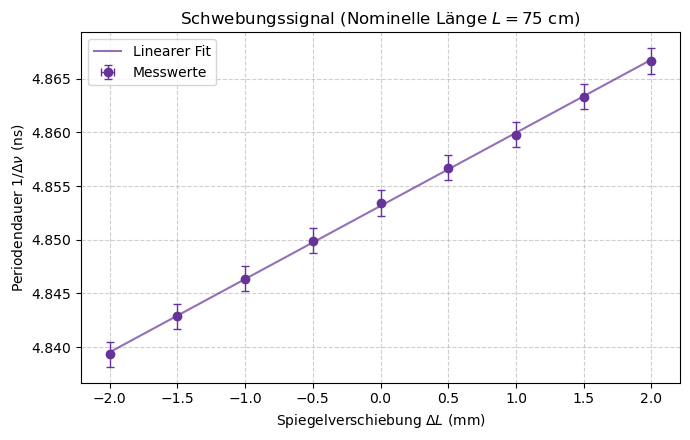

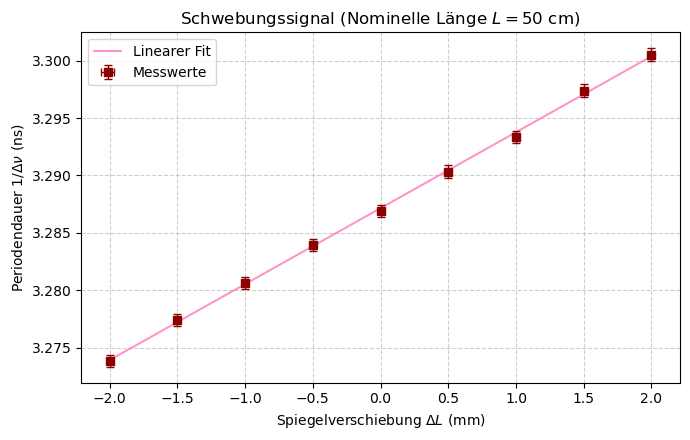

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ==========================================
# 1. MESSDATEN (Aufgabe 5)
# ==========================================
schritte_75 = np.array([4, 3, 2, 1, 0, -1, -2, -3, -4])
nu_75_MHz = np.array([206.64, 206.49, 206.34, 206.19, 206.04, 205.90, 205.77, 205.62, 205.48])

schritte_50 = np.array([4, 3, 2, 1, 0, -1, -2, -3, -4])
nu_50_MHz = np.array([305.45, 305.12, 304.82, 304.51, 304.24, 303.92, 303.64, 303.27, 302.98])

# ==========================================
# 2. MESSUNSICHERHEITEN ANNEHMEN & UMRECHNEN
# ==========================================
# Fehler Längenänderung: 0.01 mm
err_L_m = 0.01 * 1e-3 

# Fehler Frequenz: 0.05 MHz (50 kHz)
err_nu_MHz = 0.05 

# Umrechnung in SI-Einheiten
delta_L_m_75 = -schritte_75 * 0.5 * 1e-3 
delta_L_m_50 = -schritte_50 * 0.5 * 1e-3 

y_75 = 1 / (nu_75_MHz * 1e6) # Periodendauer in Sekunden
y_50 = 1 / (nu_50_MHz * 1e6) 

# Fehlerfortpflanzung für y = 1/nu (Delta_y = 1/nu^2 * Delta_nu)
err_y_75 = (1 / (nu_75_MHz * 1e6)**2) * (err_nu_MHz * 1e6)
err_y_50 = (1 / (nu_50_MHz * 1e6)**2) * (err_nu_MHz * 1e6)

# ==========================================
# 3. LINEARE REGRESSION & FEHLERFORTPFLANZUNG
# ==========================================
def linear_fit(x, m, b):
    return m * x + b

def werte_aus(x_data, y_data, label):
    popt, pcov = curve_fit(linear_fit, x_data, y_data)
    m, b = popt
    err_m, err_b = np.sqrt(np.diag(pcov))
    
    c = 2 / m
    err_c = abs(2 / m**2) * err_m
    
    L0 = b / m
    err_L0 = abs(L0) * np.sqrt((err_b / b)**2 + (err_m / m)**2)
    
    return m, b

m75, b75 = werte_aus(delta_L_m_75, y_75, "L = 75 cm")
m50, b50 = werte_aus(delta_L_m_50, y_50, "L = 50 cm")

# ==========================================
# 4. PLOTS MIT FEHLERBALKEN ERSTELLEN
# ==========================================

# --- Plot 1: L = 75 cm ---
plt.figure(figsize=(7, 4.5))

# Fit-Gerade zeichnen
plt.plot(delta_L_m_75 * 1000, linear_fit(delta_L_m_75, m75, b75) * 1e9, '-', color='rebeccapurple', alpha=0.7, label='Linearer Fit')

# Messwerte mit x- und y-Fehlerbalken (Umrechnung in mm und ns für den Plot)
plt.errorbar(delta_L_m_75 * 1000, y_75 * 1e9, 
             xerr=err_L_m * 1000, yerr=err_y_75 * 1e9, 
             fmt='o', color='rebeccapurple', label='Messwerte', capsize=3, capthick=1, elinewidth=1, zorder=5)

plt.title('Schwebungssignal (Nominelle Länge $L = 75$ cm)')
plt.xlabel('Spiegelverschiebung $\Delta L$ (mm)')
plt.ylabel('Periodendauer $1 / \Delta \\nu$ (ns)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
# plt.savefig('schwebung_75cm_error.png', dpi=300)
plt.show()

# --- Plot 2: L = 50 cm ---
plt.figure(figsize=(7, 4.5))

# Fit-Gerade zeichnen
plt.plot(delta_L_m_50 * 1000, linear_fit(delta_L_m_50, m50, b50) * 1e9, '-', color='hotpink', alpha=0.7, label='Linearer Fit')

# Messwerte mit x- und y-Fehlerbalken
plt.errorbar(delta_L_m_50 * 1000, y_50 * 1e9, 
             xerr=err_L_m * 1000, yerr=err_y_50 * 1e9, 
             fmt='s', color='darkred', label='Messwerte', capsize=3, capthick=1, elinewidth=1, zorder=5)

plt.title('Schwebungssignal (Nominelle Länge $L = 50$ cm)')
plt.xlabel('Spiegelverschiebung $\Delta L$ (mm)')
plt.ylabel('Periodendauer $1 / \Delta \\nu$ (ns)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
# plt.savefig('schwebung_50cm_error.png', dpi=300)
plt.show()